# Settings

In [ ]:
parameters_file_path = "/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/006_mouse_long/params.json"
#Simulation settings
using_simulation_data = False
rf_matrix_path = "/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/006_mouse_long/concat/1760_concat_matrix_test.npy"

#Real data settings
using_matlab_data = False       #! high RAM usage for big files -> convert mat file to npy for memory map usage and set using_simulation_data to False
matlab_rf_data_path = "/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/006_mouse_long/concat/concatenated_matrix.mat"
interpolate_data = True

#Batch processing settings
batch_processing = True
batch_size = 2                 #ignored if batch_processing is False
frames_to_process = 1760
MAX_WORKERS = 10                 #max is 12 for the current computer (10 max recommended)

#Beamforming settings
run_nsi_apodization = True
nsi_dc_offset = 0.01
other_apodization = "rectangle".lower()

#Saving parameters
save_image = True
bf_data_path = "./data_bf/"
folder_name = "mouse_long_concat"
beamformed_apodized_matrix_name = "1760_bf_concat"
angles_debbuging = False          #if true saves the angles used for the beamforming (z,x, angles, frames)


# Imports

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import json
import timeit
import os
import math
import concurrent.futures
from numba import njit
from scipy.signal import envelope, firwin
from scipy.io import loadmat

# Import parameters

In [33]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [34]:
def add_extra_params(params):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"] 

    return params

In [35]:
params = load_parameters(parameters_file_path)
params = add_extra_params(params)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling
C = params["rf"]["C"] #speed of sound

print(f"Max acquisition depth : {params["array"]["acq_depth"][1]} m") #v = d / t => d = v * t / 2 (round trip) with t = sample_step * samples

Max acquisition depth : 0.012 m


# Create workspace

In [36]:
if not os.path.exists(f"{bf_data_path}{folder_name}"):
    os.makedirs(f"{bf_data_path}{folder_name}")
    print(f"Folder {bf_data_path}{folder_name} doesn't exist. Setting up the folder.")

os.makedirs(f"{bf_data_path}{folder_name}/beamformed_final", exist_ok=True)
os.makedirs(f"{bf_data_path}{folder_name}/beamformed_apodized", exist_ok=True)
os.makedirs(f"{bf_data_path}{folder_name}/images", exist_ok=True)

Folder ./data_bf/mouse_long_concat doesn't exist. Setting up the folder.


# Import RF matrix

In [37]:
def load_rf_data(rf_matrix_path, matlab_rf_data_path, desired_frames : list, using_simulation_data, using_matlab_data, nb_angles):
    debug_statement = ""

    if using_simulation_data:

        rf_matrix_summed = np.load(rf_matrix_path)
        if rf_matrix_summed.ndim == 3:
                rf_matrix_summed = rf_matrix_summed[:, :, :, np.newaxis]
        rf_matrix_summed = rf_matrix_summed[:,:,:,desired_frames[0]:desired_frames[1]]
        debug_statement += f"Imported RF matrix with shape:  {rf_matrix_summed.shape}"

    else:
        if using_matlab_data:
            rf_matrix_summed = loadmat(matlab_rf_data_path)
            rf_matrix_summed = list(rf_matrix_summed.values())[-1]
            if rf_matrix_summed.ndim == 3:
                rf_matrix_summed = rf_matrix_summed[:, :, :, np.newaxis]
            rf_matrix_summed = rf_matrix_summed[:,:,:,desired_frames[0]:desired_frames[1]]
            rf_matrix_summed = np.float64(rf_matrix_summed)
            debug_statement += f"Imported RF matrix with shape: {rf_matrix_summed.shape}"
        else:
            rf_matrix_summed = np.lib.format.open_memmap(rf_matrix_path, mode='r')
            rf_matrix_summed = rf_matrix_summed[:,:,:,desired_frames[0]:desired_frames[1]]
            # if rf_matrix_summed.ndim == 3:
            #         rf_matrix_summed = rf_matrix_summed[:, :, :, np.newaxis]
            debug_statement += f"Imported RF matrix with shape:  {rf_matrix_summed.shape}"
            

    return rf_matrix_summed, debug_statement

# Interpolation

In [38]:
@njit()
def zero_stuffing(rf_matrices_summed, interpolation_factor, upsampled_samples):
    interpolation_factor = interpolation_factor - 1
    
    new_matrices_summed = np.zeros((upsampled_samples, rf_matrices_summed.shape[1], rf_matrices_summed.shape[2]))
    
    for i in range(rf_matrices_summed.shape[2]): #for each angle
        for j in range(rf_matrices_summed.shape[1]): #for each transducer
            for k in range(rf_matrices_summed.shape[0]): #for each sample
                idx_new = k + (interpolation_factor * k)
                new_matrices_summed[idx_new, j, i] = rf_matrices_summed[k, j, i]

    return new_matrices_summed

In [39]:
def get_filtered_matrices(zero_stuffed_rf_matrices_summed, sampling_frequency, interpolation_factor):
    filtered_rf_matrices_summed = np.zeros((zero_stuffed_rf_matrices_summed.shape[0], zero_stuffed_rf_matrices_summed.shape[1], zero_stuffed_rf_matrices_summed.shape[2]))
    
    n_taps = 129
    cutoff_freq = sampling_frequency / 2

    filtering_function = firwin(n_taps, cutoff_freq, fs=sampling_frequency * interpolation_factor, window='hamming') * interpolation_factor

    for i in range(0, zero_stuffed_rf_matrices_summed.shape[2]): #for each angle
        for j in range(0, zero_stuffed_rf_matrices_summed.shape[1]): #for each transducer
            filtered_rf_matrices_summed[:,j,i] = np.convolve(zero_stuffed_rf_matrices_summed[:,j,i], filtering_function, mode='same')

    return filtered_rf_matrices_summed

# Effective aperture

In [40]:
@njit()
def find_object_effective_aperture(current_position, current_depth, aperture, array_length, pitch):
    effective_array_length =  current_depth / aperture
    first_transducer = -1
    transducers_in_effective_array = 0
    
    for j in range(0, array_length):
        if j*pitch >= current_position - effective_array_length / 2 and j*pitch <= current_position + effective_array_length / 2:
            if first_transducer == -1:
                first_transducer = j
            transducers_in_effective_array += 1
    
    return effective_array_length, transducers_in_effective_array, first_transducer   

# Apodization

## Apodization functions

In [41]:
@njit()
def generate_zm_apodization(first_transducer, transducers_in_effective_array, array_length, offset=0, mirror=False):
    result = np.zeros(array_length) + offset
    
    for transducer_idx in range(array_length):
        if transducer_idx - first_transducer >= 0:  # making sure we are in the effective array range
            transducer_relative_idx = transducer_idx - first_transducer
            if 0 <= transducer_relative_idx < transducers_in_effective_array / 2:
                result[transducer_idx] = (-1 if mirror else 1) + offset
            elif transducers_in_effective_array / 2 <= transducer_relative_idx < transducers_in_effective_array:
                result[transducer_idx] = (1 if mirror else -1) + offset

    return result

@njit()
def generate_rectangle_apodization(current_position, effective_array_length, array_length, amount_kept, pitch, offset=0):
    result = np.zeros(array_length) + offset
    
    half_array = effective_array_length / 2
    amount_trimmed = (1 - amount_kept) * half_array
    
    for transducer_idx in range(array_length):
        position = transducer_idx * pitch
        lower_bound = current_position - half_array + amount_trimmed
        upper_bound = current_position + half_array - amount_trimmed
        
        if lower_bound <= position <= upper_bound:
            result[transducer_idx] = 1 + offset
        else:
            result[transducer_idx] = 0 + offset
    
    return result

In [42]:
@njit()
def apodization_wrapper(apodization_function, first_transducer, transducers_in_effective_array, effective_array_length, array_length, current_position, amount_kept, pitch, offset=0, mirror=False):
    
    match apodization_function:
        case "zm":
            return generate_zm_apodization(first_transducer, transducers_in_effective_array, array_length, offset=0, mirror=False)
        case "dc1":
            return generate_zm_apodization(first_transducer, transducers_in_effective_array, array_length, offset=nsi_dc_offset, mirror=False)
        case "dc2":
            return generate_zm_apodization(first_transducer, transducers_in_effective_array, array_length, offset=nsi_dc_offset, mirror=True)
        case "rectangle":
            return generate_rectangle_apodization(current_position, effective_array_length, array_length, amount_kept, pitch, offset=0)
        case "":
            return np.ones(array_length)
        case _:
            return np.ones(array_length)

Effective array length:  0.004000158177791838 first_transducer:  28 transducers_in_effective_array:  45


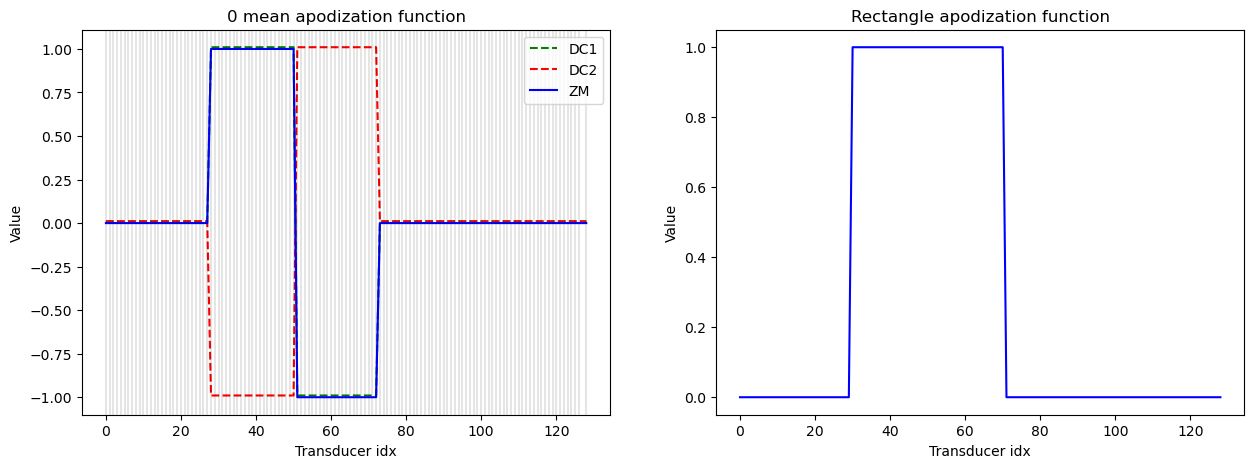

In [43]:
effective_array_length, transducers_in_effective_array, first_transducer = find_object_effective_aperture(200*2.25e-5, 1331*0.0095/3161, params["array"]["aperture"], params["array"]['length'], params["array"]["pitch"])
print("Effective array length: ", effective_array_length, "first_transducer: ", first_transducer, "transducers_in_effective_array: ", transducers_in_effective_array)

apodization_zm = apodization_wrapper("zm", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.9, params["array"]["pitch"])
apodization_dc1 = apodization_wrapper("dc1", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.9, params["array"]["pitch"])
apodization_dc2 = apodization_wrapper("dc2", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.9, params["array"]["pitch"])
apodization_rectangle = apodization_wrapper("rectangle", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.9, params["array"]["pitch"])

fig, ax = plt.subplots(1,2, figsize=(15, 5))

ax[0].plot(pos, apodization_dc1, color='g', ls='--', label='DC1')
ax[0].plot(pos, apodization_dc2, color='r', ls='--', label ='DC2')
ax[0].plot(pos, apodization_zm, color='b', label='ZM')
for x in pos:
    ax[0].axvline(x=x, color='black', ls='-', alpha=0.1)
ax[0].set_title('0 mean apodization function')
ax[0].set_xlabel('Transducer idx')
ax[0].set_ylabel('Value')
ax[0].legend()

ax[1].plot(pos, apodization_rectangle, color='b')
ax[1].set_title('Rectangle apodization function')
ax[1].set_xlabel('Transducer idx')
ax[1].set_ylabel('Value')
plt.show()

# Envelopes

In [44]:
def get_envelope(bf_matrix, frames):
    lateral_resolution = bf_matrix.shape[1]
    samples = bf_matrix.shape[0]

    env = np.zeros((samples, lateral_resolution, frames))
    for i in range(0, frames):
        for j in range(0, lateral_resolution):
            env[:,j,i] = envelope(bf_matrix[:,j,i], residual=None)
    return env

# Beamforming

In [45]:
@njit()
def get_samples_depth_lateral_resolution(dx, dz, pitch, array_length, max_acquisition_depth):
    samples_for_acquisition_depth = int(max_acquisition_depth / dz)
    samples_for_array_length = int(array_length * pitch / dx)

    return samples_for_acquisition_depth, samples_for_array_length

In [46]:
def save_beamformed_data(bf_matrix, filename, destination=f"{bf_data_path}/{folder_name}/beamformed_final/"):
    np.save(f"{destination}{filename}", bf_matrix)
    print(f"Beamformed data of shape {bf_matrix.shape} saved at: {destination}{filename}.npy")

In [47]:
@njit(parallel=True)
def beamforming_opt(rf_summed_matrices, nx, nz, dx, dz, x0, z0, delay0, pitch, c, array_length, samples, sampling_rate, aperture, apodization_function, using_real_data, frames, debug, angles = [0]):

    #var initrt
    fixed_delay = delay0 / c

    bf_matrix = np.zeros((nz, nx, len(angles), frames), dtype=np.float64)

    cos_angles = [np.cos(angle * np.pi/180) for angle in angles]
    sin_angles = [np.sin(angle * np.pi/180) for angle in angles]

    t0_delay = [fixed_delay for _ in range(len(angles))]

    if using_real_data:
        t0_delay = [t0_delay[i] + ((array_length * pitch) * sin_angle / c) * (angles[i] < 0) for i, sin_angle in enumerate(sin_angles)]
        min_t0_delay = min(t0_delay)
        # t0_delay = [t0_delay[i] - min_t0_delay for i in range(len(t0_delay))]

    if debug:
        print("\n" + "="*60)
        print(f"✓ BEAMFORMING CONFIGURATION:")
        print(f"  • Resolution: {nx} x {nz}")
        print(f"  • Acquisition depth:",2,"m",f"({nz} samples)")
        print(f"  • Fixed delay:",fixed_delay,"s", delay0, "m")
        print(f"  • Delays: ",t0_delay, " - Min delay: ",min_t0_delay, "s")
        print(f"  • Array length:",array_length * pitch,"m",f"({nx} samples)")
        print(f"  • Apodization: {apodization_function}")
        print(f"  • Processing {len(angles)} angle(s)")
        print("-"*60)

    for h in range(0, frames): #for each frame
        if debug:
            print(f"  ↳ Processing frame",h+1,f"[{h+1}/{frames}]")
    
        for i in range(0, len(angles)): #for each angle
            if debug:
                print(f"    ↳ Processing angle",angles[i],"°",f"[{i+1}/{len(angles)}]")

            for j in range(0, nx): #for each lateral res sample

                for k in range(0, nz): #for vertical res sample

                    depth = dz*k + z0   #account for intial depth / same goes for x0
                    position = dx*j + x0

                    effective_array_length, transducers_in_effective_array, first_transducer = find_object_effective_aperture(position, depth, aperture, array_length, pitch)

                    apodization = apodization_wrapper(
                        apodization_function, 
                        first_transducer, 
                        transducers_in_effective_array, 
                        effective_array_length, 
                        array_length, 
                        position, 
                        0.5, 
                        pitch
                    )   

                    for l in range(first_transducer, first_transducer + transducers_in_effective_array): #for transducers in effective array

                        delay = ((depth * cos_angles[i] + position * sin_angles[i])  + (np.sqrt(depth**2 + (l * pitch - position)**2))) / c - t0_delay[i]   #delay in s
                        
                        exact_delay_idx_float = delay * sampling_rate
                        
                        #for better accuracr, lets apply linear interpolation on our delay values
                        idx_floor = int(np.floor(exact_delay_idx_float)) #x0
                        idx_ceil = idx_floor + 1                     #x1

                        if 0 <= idx_floor and idx_ceil < samples:

                            weight_ceil = exact_delay_idx_float - idx_floor #wieght for y1
                            weight_floor = idx_ceil - exact_delay_idx_float #weight for y0

                            val_floor = rf_summed_matrices[idx_floor, l, i, h] #y0
                            val_ceil = rf_summed_matrices[idx_ceil, l, i, h] #y1

                            interpolated_value = (weight_floor * val_floor) + (weight_ceil * val_ceil) #y
                            bf_matrix[k,j,i,h] += interpolated_value * apodization[l]

    if debug:
        print("-"*60)
        print(f"✓ BEAMFORMING COMPLETE")
        print(f"  • Output shape: ", bf_matrix.shape)
        print("="*60 + "\n")
    return bf_matrix

# Run beamforming

In [48]:
def process_batch_multiprocessing(
    batch_idx, start_frame, current_batch_size, total_frames, frame_iterations_total,
    rf_matrix_path_arg, matlab_rf_data_path_arg, using_simulation_data_arg, using_matlab_data_arg,
    interpolate_data_arg, params_arg, run_nsi_apodization_arg, other_apodization_arg, apo_funcs_arg,
    C_arg, samples_arg, sampling_rate_arg,
    bf_data_path_arg, folder_name_arg, beamformed_apodized_matrix_name_arg,
    samples_for_acquisition_depth_arg, samples_for_array_length_arg
    ):
    """
    Processes a single batch of RF data frames in a separate process.

    Returns:
        tuple: (batch_idx, True) if successful, (batch_idx, False) otherwise.
    """
    try:

        #Load rf data for the current batch

        rf_matrix_summed, debug_statement = load_rf_data(
            rf_matrix_path_arg,
            matlab_rf_data_path_arg,
            [start_frame, start_frame + current_batch_size],
            using_simulation_data_arg,
            using_matlab_data_arg,
            len(params_arg["rf"]["angles"])
        )

        print(f"{'='*60}\nProcessing batch {batch_idx} [{batch_idx}/{frame_iterations_total}] (Process ID: {os.getpid()})"
            f"\n  • Processing from frame {start_frame} to frame {start_frame + current_batch_size}"
            f"\n  • Processing {current_batch_size} frame(s)"
            f"\n  • RF matrix: {debug_statement}"
            f"\n  • Running {'NSI apodizations' if run_nsi_apodization_arg else f'{other_apodization_arg} apodization'}"
            f"\n{'='*60}\n")

        actual_loaded_frames = rf_matrix_summed.shape[3]

        delay0 = params_arg["rf"]["delay0"]

        if actual_loaded_frames != current_batch_size:
             print(f"Warning: Loaded {actual_loaded_frames} frames for batch {batch_idx}, expected {current_batch_size}.")
             current_batch_size = actual_loaded_frames

        #Interpolate data
        if interpolate_data_arg:

            delay0 = params_arg["rf"]["interpolation_factor"] * params_arg["rf"]["delay0"]  #mutliplying delay by interpolation rate to make sure its correct

            rf_matrix_summed_tmp = np.zeros((params_arg["rf"]["upsampled_samples"], rf_matrix_summed.shape[1], rf_matrix_summed.shape[2], actual_loaded_frames))

            for j in range(actual_loaded_frames):
                temp_zero_stuffed = zero_stuffing(rf_matrix_summed[:,:,:,j], params_arg["rf"]["interpolation_factor"], params_arg["rf"]["upsampled_samples"])
                rf_matrix_summed_tmp[:,:,:,j] = get_filtered_matrices(temp_zero_stuffed, params_arg["rf"]["sampling_rate"], params_arg["rf"]["interpolation_factor"])

            rf_matrix_summed = rf_matrix_summed_tmp
            del temp_zero_stuffed
            del rf_matrix_summed_tmp

        #Beamforming
        bf_matrices = []

        for apo_func in apo_funcs_arg:
            bf_apodized_matrix = beamforming_opt(
                rf_matrix_summed,
                samples_for_array_length_arg,
                samples_for_acquisition_depth_arg,
                params_arg["image"]["dx"],
                params_arg["image"]["dz"],
                params_arg["image"]["x0"],
                params_arg["image"]["z0"],
                delay0,
                params_arg["array"]["pitch"],
                C_arg,
                params_arg["array"]["length"],
                samples_arg,
                sampling_rate_arg,
                params_arg["array"]["aperture"],
                apo_func,
                not using_simulation_data_arg,
                actual_loaded_frames,
                debug = False,
                angles=params_arg["rf"]["angles"]
            )
            bf_matrices.append(bf_apodized_matrix)

        if angles_debbuging and not run_nsi_apodization_arg:
            save_beamformed_data(bf_matrices[0], f"{beamformed_apodized_matrix_name_arg}_{apo_funcs_arg[0]}_angles", destination=f"{bf_data_path_arg}{folder_name_arg}/")
        
        #summing all angles in bf matries
        bf_apodized_matrices_summed = [np.sum(bf_apodized_matrices_loaded, axis=2) for bf_apodized_matrices_loaded in bf_matrices]

        #append to saved matrix using memory mapping
        output_folder = os.path.join(bf_data_path_arg, folder_name_arg, "beamformed_apodized")

        for j, apo_func in enumerate(apo_funcs_arg):
            memmap_path = os.path.join(output_folder, f"{beamformed_apodized_matrix_name_arg}_{apo_func}.npy")

            memmap_bf_matrix = np.lib.format.open_memmap(memmap_path, dtype=np.float64, mode='r+', shape=(samples_for_acquisition_depth_arg, samples_for_array_length_arg, total_frames))
            memmap_bf_matrix[:, :, start_frame : start_frame + actual_loaded_frames] = bf_apodized_matrices_summed[j]
            memmap_bf_matrix.flush() #making sure data is written to disk
            del memmap_bf_matrix

        del bf_apodized_matrices_summed
        del bf_matrices
        del rf_matrix_summed

        print("="*60 + "\n" + f"Finished processing batch {batch_idx} (Process ID: {os.getpid()})\n" + "="*60 + "\n")
        return (batch_idx, True) #return process status for easier debuging

    except Exception as e:
        print(f"!!! Error in process {os.getpid()} processing batch {batch_idx} (frames {start_frame} to {start_frame + current_batch_size}): {e}")
        import traceback
        traceback.print_exc()
        return (batch_idx, False)

In [49]:
batch_size = batch_size if batch_processing else 1

#load right parameters for batch processing 
if frames_to_process % batch_size == 0:
    frame_iterations = frames_to_process // batch_size
else:
    frame_iterations = frames_to_process // batch_size + 1

print(f"Frame iterations: {frame_iterations}")
if batch_processing:
    print(f"Batch processing with {batch_size} frames")

if interpolate_data:
    samples = params["rf"]["upsampled_samples"]
    sampling_rate = params["rf"]["upsampled_sampling_rate"]
else:
    samples = params["rf"]["samples"]
    sampling_rate = params["rf"]["sampling_rate"]

apo_funcs = ["zm", "dc1", "dc2"] if run_nsi_apodization else [other_apodization]

samples_for_acquisition_depth, samples_for_array_length = get_samples_depth_lateral_resolution(params["image"]["dx"], params["image"]["dz"], params["array"]["pitch"], params["array"]["length"], params["array"]["acq_depth"][1])

if params["image"]["nx"]:
    samples_for_array_length = params["image"]["nx"]
if params["image"]["nz"]:
    samples_for_acquisition_depth = params["image"]["nz"]

print(f"Samples for acquisition depth: {samples_for_acquisition_depth}")
print(f"Samples for array length: {samples_for_array_length}")

#create numpy matrices for batch processing
for apo_func in apo_funcs:
    apodized_bf_image = np.zeros((samples_for_acquisition_depth, samples_for_array_length, frames_to_process), dtype=np.float64)
    save_beamformed_data(apodized_bf_image, f"{beamformed_apodized_matrix_name}_{apo_func}", destination=f"{bf_data_path}{folder_name}/beamformed_apodized/")

Frame iterations: 880
Batch processing with 2 frames
Samples for acquisition depth: 200
Samples for array length: 256
Beamformed data of shape (200, 256, 1760) saved at: ./data_bf/mouse_long_concat/beamformed_apodized/1760_bf_concat_rectangle.npy


In [50]:
#run multiprocessing
start_time = timeit.default_timer()

print(f"\nStarting process pool with {MAX_WORKERS} workers.")
print(f"Total frames to process: {frames_to_process}")
print(f"Batch size: {batch_size}")
print(f"Total batches: {frame_iterations}")
futures = []

with concurrent.futures.ProcessPoolExecutor(max_workers=MAX_WORKERS) as executor:
    last_batch_flag = False

    for i in range(0, frames_to_process, batch_size):
        if last_batch_flag:
            break #for safety
        current_batch_start_frame = i

        # last batch nb of frames if batch size isnt multiple of frames_to process - spot last batch
        if current_batch_start_frame + batch_size >= frames_to_process:
            current_batch_actual_size = frames_to_process - current_batch_start_frame
            last_batch_flag = True
            print(f"Last batch identified: Start Frame {current_batch_start_frame}, Size {current_batch_actual_size}")
        else:
            current_batch_actual_size = batch_size

            #set last batch if we have batch size multiple of frames to process
            last_batch_flag = (current_batch_start_frame + batch_size == frames_to_process)

        if current_batch_actual_size <= 0:
            print(f"Skipping batch starting at frame {current_batch_start_frame} due to zero or negative size.")
            continue

        batch_index = int(i / batch_size) + 1

        #submit task to process pool
        futures.append(executor.submit(
            process_batch_multiprocessing,
            #batch args
            batch_idx=batch_index,
            start_frame=current_batch_start_frame,
            current_batch_size=current_batch_actual_size,
            total_frames=frames_to_process,
            frame_iterations_total=frame_iterations,
            #other args
            rf_matrix_path_arg=rf_matrix_path,
            matlab_rf_data_path_arg=matlab_rf_data_path,
            using_simulation_data_arg=using_simulation_data,
            using_matlab_data_arg=using_matlab_data,
            interpolate_data_arg=interpolate_data,
            params_arg=params,
            run_nsi_apodization_arg=run_nsi_apodization,
            other_apodization_arg=other_apodization,
            apo_funcs_arg=apo_funcs,
            C_arg=C,
            samples_arg=samples,
            sampling_rate_arg=sampling_rate,
            bf_data_path_arg=bf_data_path,
            folder_name_arg=folder_name,
            beamformed_apodized_matrix_name_arg=beamformed_apodized_matrix_name,
            samples_for_acquisition_depth_arg=samples_for_acquisition_depth,
            samples_for_array_length_arg=samples_for_array_length
        ))

    #evluate all processes
    print("\nWaiting for all batches to complete...\n")
    results = []
    num_success = 0
    num_failed = 0
    for future in concurrent.futures.as_completed(futures):
        try:
            batch_num, success = future.result() #get function output 
            if success:
                num_success += 1
            else:
                num_failed += 1
                print(f"Batch {batch_num} failed.")
            results.append(success)
        except Exception as exc:
            print(f'A batch generated an exception during execution/retrieval: {exc}')
            num_failed += 1
            results.append(False)

#end of multiprocessing
end_time = timeit.default_timer()

print("\n--- Processing Summary ---\n")
print(f"Total Batches: {frame_iterations}")
print(f"Successful Batches: {num_success}")
print(f"Failed Batches: {num_failed}")
if num_failed == 0:
    print("\nAll batches processed successfully.")
else:
    print(f"\n{num_failed} batch(es) failed. Check logs above.")
print(f"\nTotal Beamforming took: {end_time - start_time:.2f} seconds")


Starting process pool with 10 workers.
Total frames to process: 1760
Batch size: 2
Total batches: 880
Processing batch 1 [1/880] (Process ID: 77992)
  • Processing from frame 0 to frame 2
  • Processing 2 frame(s)
  • RF matrix: Imported RF matrix with shape:  (768, 128, 16, 2)
  • Running rectangle apodization

Processing batch 2 [2/880] (Process ID: 77993)
  • Processing from frame 2 to frame 4
  • Processing 2 frame(s)
  • RF matrix: Imported RF matrix with shape:  (768, 128, 16, 2)
  • Running rectangle apodization

Processing batch 4 [4/880] (Process ID: 77995)
  • Processing from frame 6 to frame 8
  • Processing 2 frame(s)
  • RF matrix: Imported RF matrix with shape:  (768, 128, 16, 2)
  • Running rectangle apodization
Processing batch 3 [3/880] (Process ID: 77994)
  • Processing from frame 4 to frame 6
  • Processing 2 frame(s)
  • RF matrix: Imported RF matrix with shape:  (768, 128, 16, 2)
  • Running rectangle apodization
Processing batch 8 [8/880] (Process ID: 77999)
  • 

# Apply NSI 

In [51]:
if run_nsi_apodization:

    bf_env_nsi = np.zeros((samples_for_acquisition_depth, samples_for_array_length, frames_to_process))

    memmap_bf_matrix_zm = np.load(f"{bf_data_path}{folder_name}/beamformed_apodized/{beamformed_apodized_matrix_name}_zm.npy")
    memmap_bf_matrix_dc1 = np.load(f"{bf_data_path}{folder_name}/beamformed_apodized/{beamformed_apodized_matrix_name}_dc1.npy")
    memmap_bf_matrix_dc2 = np.load(f"{bf_data_path}{folder_name}/beamformed_apodized/{beamformed_apodized_matrix_name}_dc2.npy")

    memmap_bf_matrix_zm = get_envelope(memmap_bf_matrix_zm, frames=frames_to_process)
    memmap_bf_matrix_dc1 = get_envelope(memmap_bf_matrix_dc1, frames=frames_to_process)
    memmap_bf_matrix_dc2 = get_envelope(memmap_bf_matrix_dc2, frames=frames_to_process)

    for i in range(0, frames_to_process):
        bf_env_nsi[:,:,i] = (memmap_bf_matrix_dc1[:,:,i] + memmap_bf_matrix_dc2[:,:,i]) / 2 - memmap_bf_matrix_zm[:,:,i]

    save_beamformed_data(bf_env_nsi, f"{beamformed_apodized_matrix_name}_env_nsi", destination=f"{bf_data_path}{folder_name}/beamformed_apodized/")
    
    del memmap_bf_matrix_zm
    del memmap_bf_matrix_dc1
    del memmap_bf_matrix_dc2
    del bf_env_nsi

# Sum frames

In [52]:
bf_frames_path = os.path.join(bf_data_path, folder_name, "beamformed_apodized") 
bf_frames = np.load(f"{bf_frames_path}/{beamformed_apodized_matrix_name}_{"env_nsi" if run_nsi_apodization else other_apodization}.npy")

bf_final_path = os.path.join(bf_data_path, folder_name, "beamformed_final")
bf_final = np.sum(bf_frames, axis=2)
save_beamformed_data(bf_final, f"{beamformed_apodized_matrix_name}_{"env_nsi" if run_nsi_apodization else other_apodization}", destination=f"{bf_final_path}/")

del bf_final
del bf_frames

Beamformed data of shape (200, 256) saved at: ./data_bf/mouse_long_concat/beamformed_final/1760_bf_concat_rectangle.npy


## Show beamformed image

In [53]:
int(params["image"]["z0"] / params["image"]["dz"])

66

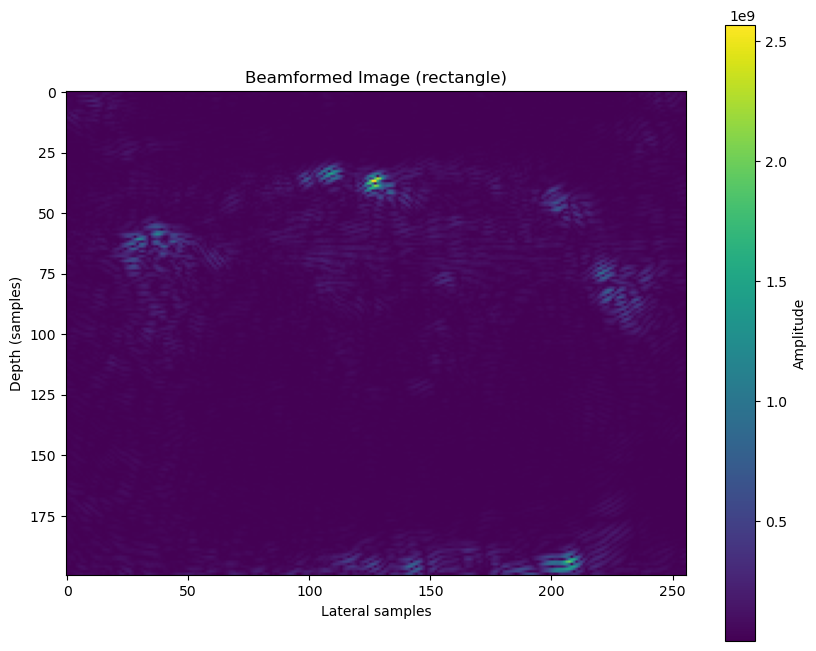

In [54]:
bf_image = np.load(f"{bf_data_path}{folder_name}/beamformed_final/{beamformed_apodized_matrix_name}_{"env_nsi" if run_nsi_apodization else other_apodization}.npy")

pixel_width = params["image"]["dx"]
pixel_height = params["image"]["dz"]
physical_aspect = pixel_width / pixel_height

plt.figure(figsize=(10, 8))
plt.imshow(np.abs(bf_image), cmap='viridis', aspect=physical_aspect)

plt.title(f"Beamformed Image ({'env_nsi' if run_nsi_apodization else other_apodization})")

plt.xlabel("Lateral samples")
plt.ylabel("Depth (samples)")

plt.colorbar(label="Amplitude") 

if save_image:
    plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_apodized_matrix_name}_{"env_nsi" if run_nsi_apodization else other_apodization}.png")
plt.show()

## Observe RF

Matrix shape: (1535, 128, 16)


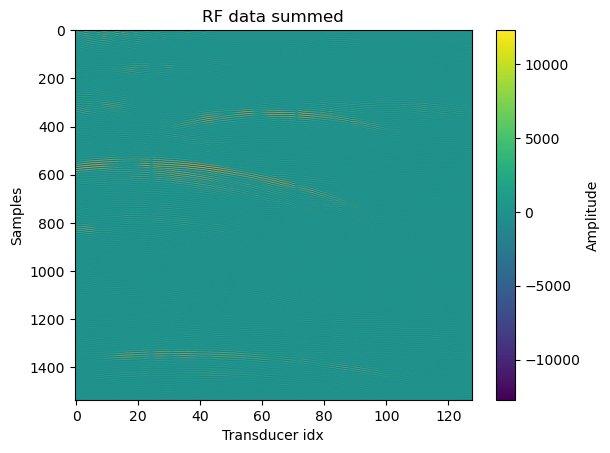

In [55]:
rf_matrix_plot, debug_statement = load_rf_data(
            rf_matrix_path,
            matlab_rf_data_path,
            [0, 1],
            using_simulation_data,
            using_matlab_data, 
            len(params["rf"]["angles"])
        )

rf_matrix_plot = np.reshape(rf_matrix_plot, (rf_matrix_plot.shape[0], rf_matrix_plot.shape[1], rf_matrix_plot.shape[2]))

if interpolate_data:
    rf_matrix_plot_tmp = np.zeros((params["rf"]["upsampled_samples"], rf_matrix_plot.shape[1], rf_matrix_plot.shape[2]))

    temp_zero_stuffed = zero_stuffing(rf_matrix_plot, params["rf"]["interpolation_factor"], params["rf"]["upsampled_samples"])
    rf_matrix_plot_tmp[:,:,:] = get_filtered_matrices(temp_zero_stuffed, params["rf"]["sampling_rate"], params["rf"]["interpolation_factor"])
    rf_matrix_plot = rf_matrix_plot_tmp
    del temp_zero_stuffed
    del rf_matrix_plot_tmp

print(f"Matrix shape: {rf_matrix_plot.shape}")

#plotting
plt.imshow(rf_matrix_plot[:,:,0], cmap='viridis', aspect='auto')
plt.title('RF data summed')
plt.xlabel('Transducer idx')
plt.ylabel('Samples')
plt.colorbar(label='Amplitude')
plt.show()